# 04 · Ensemble dan Evaluasi

Notebook ini menjelaskan **model final, cara mengevaluasinya secara jujur, dan hasilnya**.

## 1. Protokol evaluasi

| Data | Fungsi |
|---|---|
| `train` | melatih model |
| `val` | memilih arsitektur dan hyperparameter (early stopping) |
| `test` | pemeriksaan di template yang belum pernah dilihat |
| **Validasi silang per template (5 lipatan × 3 ulangan)** | **acuan utama**, karena satu split hanya berisi beberapa template per label sehingga skornya bergoyang. Pembagi lipatannya dibuat sendiri (`common.grouped_folds`): deterministik, stratified per label, dan tidak bergantung versi scikit-learn |
| `manual_test` (100 pesan) | ditulis sendiri; dipakai untuk analisis error, jadi berstatus data pengembangan |
| `manual_test_blind` (30 pesan) | **dibuka satu kali** setelah model dibekukan (dikunci dengan file lock) |

**Metrik: macro F1**: rata-rata F1 dari kelima kelas dengan bobot sama, sehingga kelas kecil atau sulit (Other) tidak tertutup oleh kelas lain. *Accuracy* ikut dicatat.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

# Notebook ini berada di folder notebooks/; pindah ke root proyek agar path data/ dan src/ konsisten
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 170)
SEED = 42
print("Root proyek:", ROOT)

Root proyek: c:\Users\asus\firaza-custom-order


## 2. Ensemble: menggabungkan dua model

**Ensemble final** = 0,5 × probabilitas CNN (rata-rata 3 seed) + 0,5 × probabilitas TF-IDF + Logistic Regression.
Alasannya: dua model dengan cara belajar berbeda membuat **kesalahan yang berbeda**, sehingga rata-ratanya lebih stabil daripada masing-masing.
Sel berikut menghitung validasi silang per template untuk tiga kandidat (15 pelatihan; beberapa menit di CPU).

In [2]:
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from common import load_data, prep, LABELS, LABEL2ID, grouped_folds
from train_baseline import make_pipeline
from train_keras import build_model

full, sp = load_data("data")
Xall = np.array(prep(full.text), dtype=object)
yall = full.label.map(LABEL2ID).values
groups = full.template_id.values

rows = []
for r, fold, a, b in grouped_folds(groups, yall, k=5, repeats=3):
    xa, xb = list(Xall[a]), list(Xall[b])
    lr = make_pipeline(LogisticRegression(C=1, max_iter=5000, random_state=SEED)).fit(np.array(xa), yall[a])
    p_lr = lr.predict_proba(np.array(xb))
    probs = []
    for seed in range(2):
        tf.keras.utils.set_random_seed(100 + seed)
        m = build_model("cnn", xa)
        m.fit(tf.constant(xa), yall[a], epochs=10, batch_size=32, verbose=0)
        probs.append(m.predict(tf.constant(xb), verbose=0, batch_size=128))
    p_cnn = np.mean(probs, axis=0)
    for name, p in {"TF-IDF + LogReg": p_lr, "CNN": p_cnn, "Ensemble CNN + LogReg": 0.5 * p_cnn + 0.5 * p_lr}.items():
        rows.append({"ulangan": r, "lipatan": fold, "model": name, "macro_f1": f1_score(yall[b], p.argmax(1), average="macro")})
    print(f"ulangan {r + 1}/3, lipatan {fold + 1}/5 selesai")
cv = pd.DataFrame(rows)
summary = cv.groupby("model", sort=False).macro_f1.agg(["mean", "std"]).round(3)
summary

ulangan 1/3, lipatan 1/5 selesai
ulangan 1/3, lipatan 2/5 selesai
ulangan 1/3, lipatan 3/5 selesai
ulangan 1/3, lipatan 4/5 selesai
ulangan 1/3, lipatan 5/5 selesai
ulangan 2/3, lipatan 1/5 selesai
ulangan 2/3, lipatan 2/5 selesai
ulangan 2/3, lipatan 3/5 selesai
ulangan 2/3, lipatan 4/5 selesai
ulangan 2/3, lipatan 5/5 selesai
ulangan 3/3, lipatan 1/5 selesai
ulangan 3/3, lipatan 2/5 selesai
ulangan 3/3, lipatan 3/5 selesai
ulangan 3/3, lipatan 4/5 selesai
ulangan 3/3, lipatan 5/5 selesai


,mean,std
model,,
TF-IDF + LogReg,0.869,0.041
CNN,0.905,0.046
Ensemble CNN + LogReg,0.907,0.042


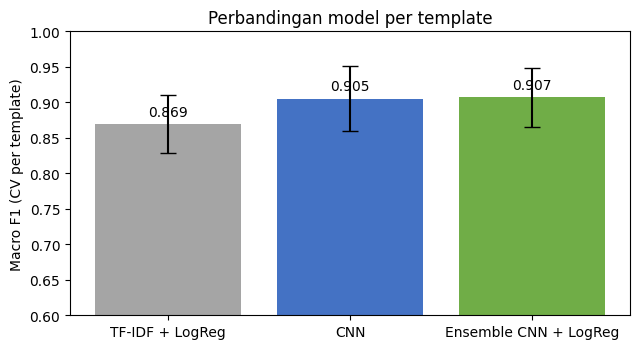

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(summary.index, summary["mean"], yerr=summary["std"], capsize=6, color=["#a5a5a5", "#4472c4", "#70ad47"])
ax.set_ylim(0.6, 1.0); ax.set_ylabel("Macro F1 (CV per template)"); ax.set_title("Perbandingan model per template")
for i, v in enumerate(summary["mean"]): ax.text(i, v + 0.012, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

Karena tiap model dievaluasi pada **lipatan yang sama**, bandingkan juga **selisih per lipatan** (perbandingan berpasangan): seberapa sering satu model lebih tinggi dari yang lain.

In [4]:
piv = cv.pivot_table(index=["ulangan", "lipatan"], columns="model", values="macro_f1")
E = "Ensemble CNN + LogReg"
for a, b in [("CNN", "TF-IDF + LogReg"), (E, "TF-IDF + LogReg"), (E, "CNN")]:
    d = piv[a] - piv[b]
    print(f"{a:22s} vs {b:16s}: selisih rata-rata {d.mean():+.3f} | lebih tinggi di {int((d > 0).sum())} dari {len(d)} lipatan")

CNN                    vs TF-IDF + LogReg : selisih rata-rata +0.036 | lebih tinggi di 13 dari 15 lipatan
Ensemble CNN + LogReg  vs TF-IDF + LogReg : selisih rata-rata +0.038 | lebih tinggi di 14 dari 15 lipatan
Ensemble CNN + LogReg  vs CNN             : selisih rata-rata +0.002 | lebih tinggi di 8 dari 15 lipatan


**Cara membaca:**

- **CNN lebih baik dari baseline TF-IDF + LogReg**, dan cukup konsisten: sekitar 3 poin lebih tinggi, di sebagian besar lipatan.
- **Ensemble dan CNN praktis sama**: selisihnya sangat kecil dan tidak konsisten antar lipatan. Ensemble tidak memberi peningkatan berarti dibanding CNN pada metrik ini.
- Jadi alasan memakai ensemble bukan "jauh lebih akurat", melainkan **lebih aman**: pada test blind (30 pesan) LogReg justru setara atau lebih tinggi daripada CNN, sehingga menggabungkan keduanya melindungi dari kelemahan salah satunya, dan probabilitasnya lebih halus untuk penanda `needs_review`.
- Simpangan baku antar lipatan masih sekitar 0,04-0,05: skor sangat bergantung pada template mana yang ada di data uji.

## 3. Hasil pada test blind (dibuka satu kali)

Model final dibekukan (`src/train_final.py`) dan dievaluasi **sekali** pada 30 pesan blind (`src/evaluate_blind.py`, dikunci file lock agar tidak bisa diulang tanpa sengaja).

| | Hasil |
|---|---|
| Accuracy | 0,90 (27 dari 30 benar) |
| **Macro F1 (ensemble final)** | **0,902** |
| Hanya CNN / hanya LogReg (informasi, bukan untuk memilih model) | 0,873 / 0,902 |

| Kelas | Precision | Recall | F1 |
|---|---|---|---|
| Ready Stock | 1,00 | 0,83 | 0,91 |
| Custom Sajadah | 1,00 | 1,00 | 1,00 |
| Custom Handuk | 1,00 | 0,83 | 0,91 |
| Hampers | 0,86 | 1,00 | 0,92 |
| Other | 0,71 | 0,83 | 0,77 |

In [5]:
import json
p = "reports/blind_metrics.json"
if os.path.exists(p):
    bm = json.load(open(p, encoding="utf-8"))
    print("Macro F1 blind :", bm["ensemble"]["macro_f1"], "| accuracy:", bm["ensemble"]["accuracy"], "| n =", bm["n"])
    print("Ditandai needs_review:", bm["needs_review_rate"])
    if os.path.exists("reports/blind_errors.csv"):
        display(pd.read_csv("reports/blind_errors.csv"))
else:
    print("reports/blind_metrics.json tidak ada di mesin ini (dihasilkan oleh evaluate_blind.py yang dijalankan sekali).")
    print("Hasilnya dicatat pada tabel di atas.")

Macro F1 blind : 0.9021 | accuracy: 0.9 | n = 30
Ditandai needs_review: 0.167


,text,label,pred,confidence
0,min box kado doang jual ga?,Ready Stock,Other,0.420
1,Handuk polosnya sudah saya beli di toko lain. Apakah di sini bisa jasa bordir inisial saja?,Custom Handuk,Other,0.493
2,"Paket hampers yang datang kurang satu mug, padahal handuk dan kartu ucapannya lengkap. Bagaimana proses ko...",Other,Hampers,0.858


### Analisis error (3 dari 30 pesan blind)

1. *"min box kado doang jual ga?"* (Ready Stock) → diprediksi Other, confidence 0,42. Bahasa sangat santai dengan kata yang jarang muncul di data latih.
2. *"Handuk polosnya sudah saya beli di toko lain. Apakah di sini bisa jasa bordir inisial saja?"* (Custom Handuk) → Other, confidence 0,49. Kasus jasa bordir untuk barang bawaan sendiri belum punya template di generator.
3. *"Paket hampers yang datang kurang satu mug, ... Bagaimana proses komplainnya?"* (Other) → Hampers, confidence **0,86**. Komplain yang menyebut banyak isi hampers; **ini satu-satunya error yang yakin**.

**Penanda `needs_review`:** prediksi dengan confidence di bawah 0,6 ditandai agar admin memeriksanya. Dua dari tiga error blind ada di bawah ambang itu; dari 25 pesan yang tidak ditandai, 24 benar. Sampelnya terlalu kecil untuk disimpulkan, dan ambang 0,6 masih nilai awal yang belum dikalibrasi.

## 4. Keterbatasan (disebut apa adanya)

- Seluruh data latih **sintetis**; performa pada pesan nyata Firaza belum teruji.
- Test blind hanya **30 pesan**: satu kesalahan menggeser skor sekitar 3 poin, jadi 0,902 dibaca sebagai perkiraan kasar.
- Karena error blind sudah dilihat, memperbaiki data berdasarkan error itu berarti memerlukan test blind baru.
- Kelas **Other** menjadi penampung pesan informal atau tidak lazim (precision paling rendah).

**Pertanyaan yang mungkin ditanyakan:** *"Kenapa ensemble?"* → ensemble sedikit di atas CNN di validasi silang (selisihnya kecil), dan di test blind LogReg setara atau lebih tinggi dari CNN; karena sinyalnya campur, menggabungkan keduanya adalah pilihan paling aman, dan probabilitasnya lebih halus. *"Kenapa percaya angka 0,902?"* → tidak sepenuhnya; n = 30, jadi pegangan utamanya validasi silang per template (sekitar 0,9).

➡️ Lanjut ke `05_inferensi_dan_genai.ipynb`.